# Analisis: EV Battery Health
Merupakan **pemeriksaan kesehatan baterai mobil listrik**. Tiap baris = 1 kali pemeriksaan 1 baterai. Ada 2.600 baterai, masing-masing diperiksa berkali-kali.

Penting untuk diketahui:
- **SOH** (State of Health) = kapasitas baterai sekarang dibanding saat baru. Di bawah **80%** dianggap sudah layak diganti.
- **chemistry** = jenis baterai (LFP, NMC, NCA, LMO).
- **cycle_count** = berapa kali baterai dicas penuh (setara).

## 1. Load data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../ev_battery_health.csv')
df.head()

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


## 2. Data understanding

In [2]:
print('Jumlah baris & kolom:', df.shape)
print('Jumlah baterai unik :', df['battery_id'].nunique())
df.info()

Jumlah baris & kolom: (50000, 35)
Jumlah baterai unik : 2600
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  str    
 1   observation_id                  50000 non-null  str    
 2   chemistry                       46541 non-null  str    
 3   manufacturer                    47539 non-null  str    
 4   vehicle_model                   46485 non-null  str    
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  str    
 7   observation_date                47784 non-null  str    
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  str    
 11  avg_daily_distance_km           47882 non-n

In [ ]:
# Missing value
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

last_service_date                 18831
vehicle_model                      3515
chemistry                          3459
fast_charge_ratio                  3405
total_energy_throughput_kwh        3370
avg_ambient_temp_c                 3282
avg_state_of_charge_pct            3138
battery_age_days                   3002
avg_depth_of_discharge_pct         2832
voltage_avg_v                      2807
humidity_pct                       2737
climate_zone                       2719
recall_flag                        2646
current_avg_a                      2487
manufacturer                       2461
bms_firmware_version               2328
altitude_m                         2322
pack_capacity_kwh                  2302
cycle_count                        2269
observation_date                   2216
avg_charging_power_kw              2140
peak_temp_during_fast_charge_c     2128
avg_daily_distance_km              2118
internal_resistance_mohm           2104
charge_time_avg_min                2091


In [4]:
# Rentang waktu
for kolom in ['manufacture_date', 'observation_date']:
    tgl = pd.to_datetime(df[kolom])
    print(kolom, ':', tgl.min().date(), 's/d', tgl.max().date())

manufacture_date : 2020-09-29 s/d 2026-07-29
observation_date : 2020-10-07 s/d 2026-09-27


In [5]:
# Statistik angka (lihat min & max untuk mencari nilai aneh)
df.describe().T[['min', '50%', 'max']]

,min,50%,max
pack_capacity_kwh,40.000000,72.600,100.000000
battery_age_days,1.000000,424.000,2184.000000
cycle_count,1.000000,371.000,5073.000000
avg_daily_distance_km,3.000000,39.300,400.000000
avg_charging_power_kw,0.902804,28.800,159.640602
fast_charge_ratio,0.000000,0.272,0.939000
avg_depth_of_discharge_pct,10.000000,65.100,100.000000
avg_state_of_charge_pct,30.900000,67.800,95.000000
charge_cycles_per_month,2.000000,18.900,57.500000
total_energy_throughput_kwh,36.400000,24134.400,402419.900000


**Temuan:** ada nilai yang tidak masuk akal, misalnya suhu ambien sampai ±83 °C dan `charge_time_avg_min` sampai ±1.232 menit.

## 3. Pertanyaan bisnis
- **Informasi** (apa yang terjadi?): *Bagaimana SOH baterai turun seiring pemakaian, dan jenis baterai mana yang paling cepat turun?* → hanya menggambarkan kondisi yang ada.
- **Strategis** (apa yang harus dilakukan?): *Kebiasaan mengisi (fast charge) seperti apa yang bikin baterai cepat rusak, dan jenis baterai mana yang sebaiknya dipilih/diprioritaskan?* → hasilnya jadi dasar keputusan.

## 4. Cleaning

In [ ]:
# 1) Tanggal jadi tipe datetime
df['manufacture_date'] = pd.to_datetime(df['manufacture_date'])
df['observation_date'] = pd.to_datetime(df['observation_date'])

# 2) chemistry kosong: isi dari baris lain milik baterai yang sama (jenis baterai tidak berubah)
df['chemistry'] = df.groupby('battery_id')['chemistry'].transform(lambda s: s.fillna(s.mode()[0]))

# 3) Outlier: potong nilai di luar persentil 1%-99%
sensor = ['avg_ambient_temp_c', 'charge_time_avg_min', 'internal_resistance_mohm',
        'peak_temp_during_fast_charge_c', 'avg_daily_distance_km', 'avg_charging_power_kw']
for kolom in sensor:
    bawah, atas = df[kolom].quantile(0.01), df[kolom].quantile(0.99)
    df[kolom] = df[kolom].clip(bawah, atas)

# 4) Kolom angka yang masih kosong: isi dengan median
angka = df.select_dtypes('number').columns
df[angka] = df[angka].fillna(df[angka].median())

# 5) Kolom teks yang masih kosong: isi 'Unknown'
teks = ['manufacturer', 'vehicle_model', 'climate_zone', 'bms_firmware_version']
df[teks] = df[teks].fillna('Unknown')

# Cek hasil. Yang masih kosong: last_service_date (= belum pernah servis) dan kolom tanggal
# (tidak dipakai di analisis ini, jadi dibiarkan)
sisa = df.isna().sum()
print(sisa[sisa > 0])
df.to_csv('ev_battery_clean.csv', index=False)

manufacture_date      1910
observation_date      2216
last_service_date    18831
dtype: int64


## 5. Visualisasi informasi: "apa yang terjadi?"
### SOH turun seiring cycle, per chemistry

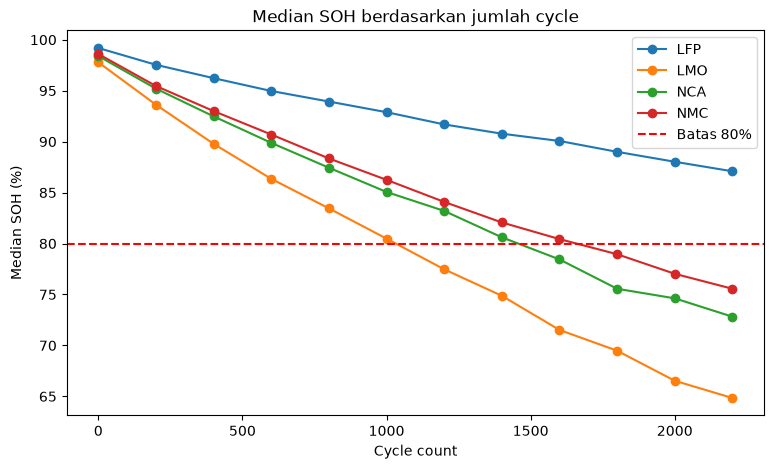

In [ ]:
df['cycle_group'] = (df['cycle_count'] // 200) * 200       
tren = df[df['cycle_group'] < 2400].groupby(['cycle_group', 'chemistry'])['state_of_health_pct'].median().unstack()

tren.plot(figsize=(9, 5), marker='o')
plt.axhline(80, color='red', linestyle='--', label='Batas 80%')
plt.title('Median SOH berdasarkan jumlah cycle')
plt.xlabel('Cycle count'); plt.ylabel('Median SOH (%)')
plt.legend(); plt.show()

**Hasil:** semua mulai dari ±98%. **LFP** turun paling landai, **LMO** paling curam dan menembus garis merah (80%) sekitar 1.000–1.200 cycle. NMC dan NCA di tengah.

### berapa persen baterai yang sudah di bawah 80%?

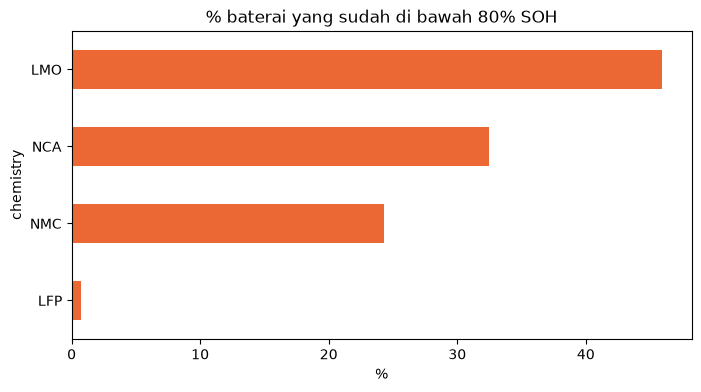

chemistry
LFP     0.8
NMC    24.3
NCA    32.5
LMO    45.9
Name: di_bawah_80, dtype: float64

In [ ]:
# Per baterai: ambil SOH paling rendah yang pernah tercatat (= kondisi terakhirnya)
per_baterai = df.groupby('battery_id').agg(chemistry=('chemistry', 'first'), soh_terendah=('state_of_health_pct', 'min'))
per_baterai['di_bawah_80'] = per_baterai['soh_terendah'] < 80

persen = per_baterai.groupby('chemistry')['di_bawah_80'].mean() * 100
persen = persen.sort_values()

persen.plot(kind='barh', figsize=(8, 4), color='#eb6834')
plt.title('% baterai yang sudah di bawah 80% SOH')
plt.xlabel('%'); plt.show()
persen.round(1)

**Hasil:** makin panjang batang, makin banyak baterai jenis itu yang sudah harus diganti. **LMO** terburuk, **LFP** hampir tidak ada.

## 6. Visualisasi strategis: "mengarah ke keputusan"
### apakah fast charge bikin baterai cepat rusak?
Kita coba bandingkan baterai yang cycle-nya mirip (600–1.000 cycle). Kolom `degradation_category` berisi Normal / Accelerated / Critical.

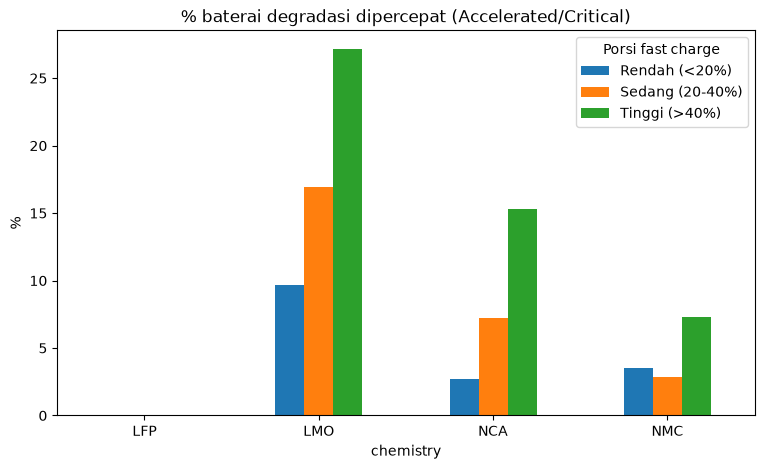

fast_charge,Rendah (<20%),Sedang (20-40%),Tinggi (>40%)
chemistry,,,
LFP,0.0,0.0,0.0
LMO,9.7,16.9,27.2
NCA,2.7,7.2,15.3
NMC,3.5,2.9,7.3


In [ ]:
mirip = df[(df['cycle_count'] >= 600) & (df['cycle_count'] <= 1000)].copy()

# Kelompokkan porsi fast charge: rendah / sedang / tinggi
mirip['fast_charge'] = pd.cut(mirip['fast_charge_ratio'], [-0.01, 0.2, 0.4, 1],
                            labels=['Rendah (<20%)', 'Sedang (20-40%)', 'Tinggi (>40%)'])
mirip['rusak_cepat'] = mirip['degradation_category'] != 'Normal'

hasil = mirip.groupby(['chemistry', 'fast_charge'])['rusak_cepat'].mean().unstack() * 100
hasil.plot(kind='bar', figsize=(9, 5))
plt.title('% baterai degradasi dipercepat (Accelerated/Critical)')
plt.ylabel('%'); plt.xticks(rotation=0); plt.legend(title='Porsi fast charge')
plt.show()
hasil.round(1)

**Hasil:** pada tiap jenis baterai, makin tinggi fast charge → makin banyak yang rusak lebih cepat (kenaikan paling terasa di **LMO** dan **NCA**). **LFP** nyaris tidak terpengaruh.

### Tabel perbandingan chemistry

In [10]:
perbandingan = pd.DataFrame({
    'jumlah_baterai': per_baterai.groupby('chemistry').size(),
    'SOH_median_terendah': per_baterai.groupby('chemistry')['soh_terendah'].median(),
    '%_di_bawah_80': persen,
    '%_rusak_cepat_(fast_charge_tinggi)': hasil['Tinggi (>40%)'],
}).round(1).sort_values('%_di_bawah_80')
perbandingan

,jumlah_baterai,SOH_median_terendah,%_di_bawah_80,%_rusak_cepat_(fast_charge_tinggi)
chemistry,,,,
LFP,784,92.7,0.8,0.0
NMC,890,87.3,24.3,7.3
NCA,545,84.3,32.5,15.3
LMO,381,81.5,45.9,27.2


## 7. Insight & rekomendasi
**Insight: Apa yang sedang/sudah terjadi**
1. Jenis baterai paling menentukan: **LFP** paling awet, **LMO** paling cepat turun, **NMC/NCA** di tengah.
2. **Fast charge** tidak terlalu menurunkan SOH secara langsung, tetapi **memperbesar peluang baterai rusak lebih cepat**, terutama pada LMO dan NCA.

**Informasi Strategis: Untuk memutuskan apa yang harus dilakukan**
1. Untuk kendaraan yang dipakai berat atau sering fast charge, **pilih LFP**.
2. Baterai **LMO dan NCA** diprioritaskan untuk dipantau, diganti, atau dipakai ulang (second-life).
3. Batasi porsi fast charge (idealnya **di bawah 40%** dari total pengisian) pada LMO, NCA, dan NMC.